# Fitting Eddy Currents with Using Inverse Laplace

The NMR probe is made to measure the eddy currents in different places within the imaging volume.

### Imports

In [1]:
from matipo import SEQUENCE_DIR, GLOBALS_DIR
import pandas as pd

In [2]:
from user_interface.fitting import Fit
fit = Fit()

Found: C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\data


### Load Data

In [3]:
probe_axis = "X"
gradient = "X"

df_, seq_par, g_hzpm = fit.get_data(probe_axis, gradient)

Scan parameters for loaded sequence:
{'offsets': [0, 0, 0, 0], 'a_pulse': 0.45, 't_pulse': 2.9999999999999997e-05, 't_dw': 1e-05, 'n_samples': 100, 'g_read': array([0.1, 0. , 0. ]), 'rx_chan_list': (3, 0, 1), 'pre_emphasis': False, 'b0': False, 'protocols': 'start_up_setting.txt', 'protocol_name': '', 'probe_axis': 'X', 'n_scans': 10, 'flip_angle': 4.5, 'n_pulses': 30, 'apodisation': 100, 't_acq_delay': 9.999999999999999e-05, 't_grad': 10.0, 't_ramp': 0.00025, 't_wait': 0.008, 't_end': 10.0, 't_next': 5, 'select_g': 'X', 'g_val': 0.1, 'tx_chan': 0, 'scan_type': 'measure_ec'}


### Gradient Fitting

N_tau: 1000, lam: 0.01, tau_min: 0.0001, tau_max: 10, N_exp_max: 3, type_: E, MAX_EXP: 4
E: x.max=0.001784553051270342
E: n_peaks=3
fit_A guess: [0.07340793 0.04803599 0.0355004 ]
fit_tau guess: [0.22822245 0.04005001 0.00605037]
df_fitE: 
Parameter    df_fit
       A0 -0.002202
       A1  0.062856
     tau1  0.272118
       A2  0.056673
     tau2  0.053684
       A3  0.037123
     tau3  0.006896
       A4  0.000000
     tau4  0.000000


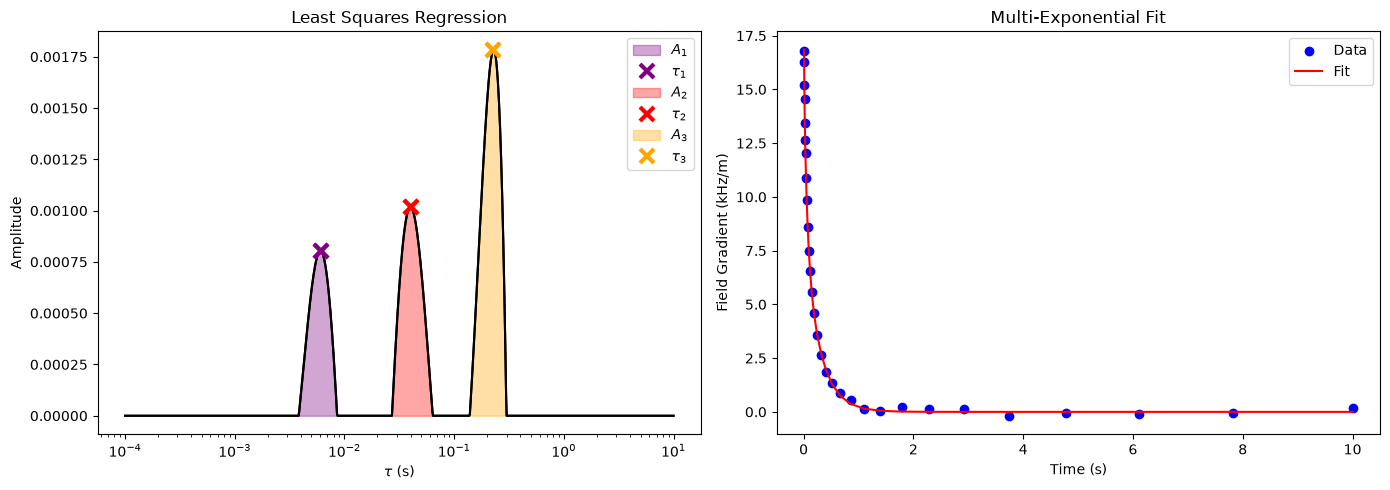

Maximum residuals variation: 524.75Hz/m
Std Dev of difference: 123.16Hz/m


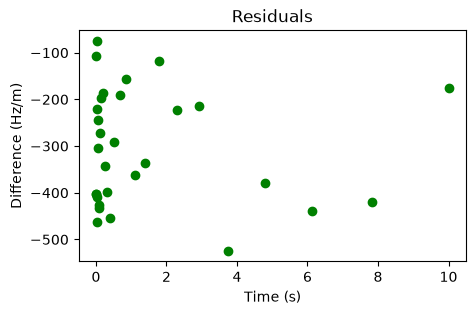

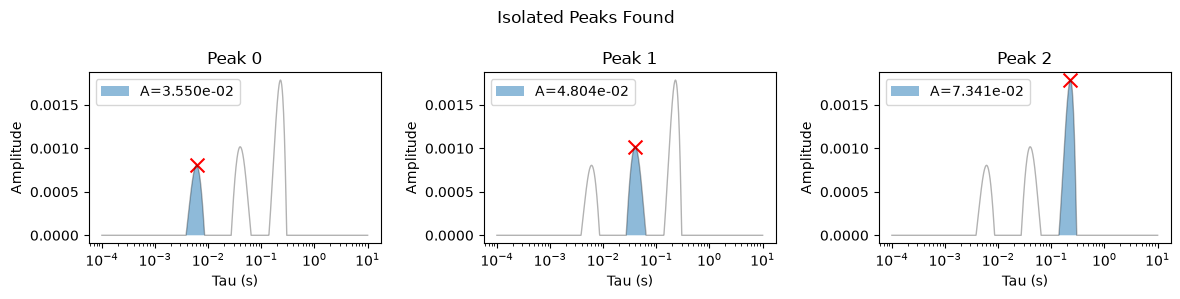

In [4]:
N_tau = 1000
lam = 1e-2
tau_min = 1e-4
tau_max = 10
N_exp_max = 3

df_fitE, fitted_values, taus, x, props, pk, fit_params = fit.fit_inv(N_tau, 
                                                                   lam, 
                                                                   tau_min, 
                                                                   tau_max, 
                                                                   df_["E(t)"], 
                                                                   df_["times (s)"],
                                                                   N_exp_max, 
                                                                   type_ = "E")

fit.plot_fit(df_, taus, x, fitted_values, props, pk, N_exp_max, type_ = "E")
var_max, std_diff = fit.plot_residuals(df_, fitted_values, type_ = "E")
fit.plot_isolated_peaks(props, pk, x, taus)

### Save Gradient df

In [5]:
fit.save_fit(df_fitE, type_ = "E")

Saved df to C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\data\Measure_EC\Xgrad_Xeddy/df_fitE.csv


### Offset Fitting

N_tau: 1000, lam: 0.001, tau_min: 0.0001, tau_max: 100, N_exp_max: 1, type_: B0, MAX_EXP: 4
B0: x.max=0.0003356007509196466
B0: n_peaks=8
fit_A guess: [np.float64(0.020298372048871326), np.float64(0.020298372048871326)]
fit_tau guess: [np.float64(0.0029612254379880344), np.float64(0.0029612254379880344)]
df_fitB0: 
Parameter    df_fit
       A0 -0.000018
       A1 -0.046449
     tau1  0.047002
       A2  0.045978
     tau2  0.045761
       A3  0.000000
     tau3  0.000000
       A4  0.000000
     tau4  0.000000


,Parameter,df_fit
0,A0,-0.000018
1,A1,-0.046449
2,tau1,0.047002
3,A2,0.045978
4,tau2,0.045761
5,A3,0.000000
6,tau3,0.000000
7,A4,0.000000
8,tau4,0.000000


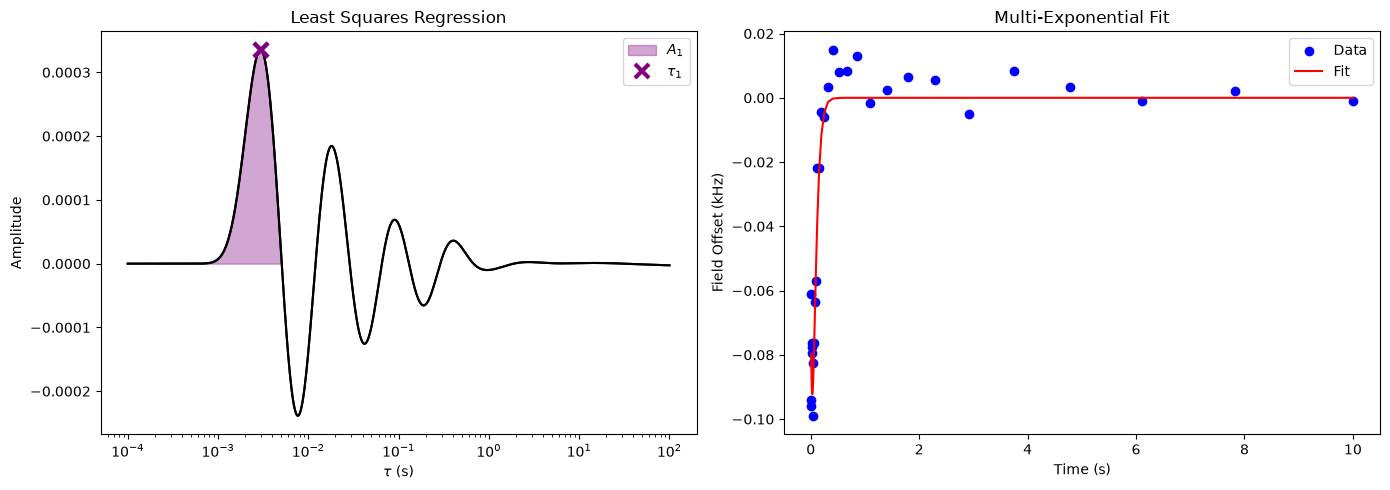

Maximum residuals variation: 20.3Hz
Std Dev of difference: 7.97Hz


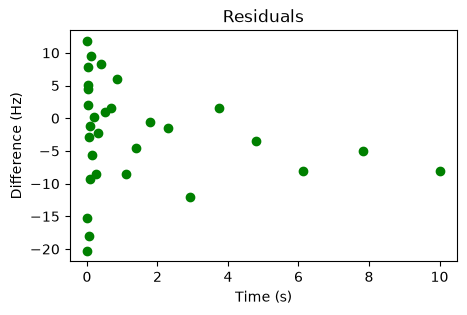

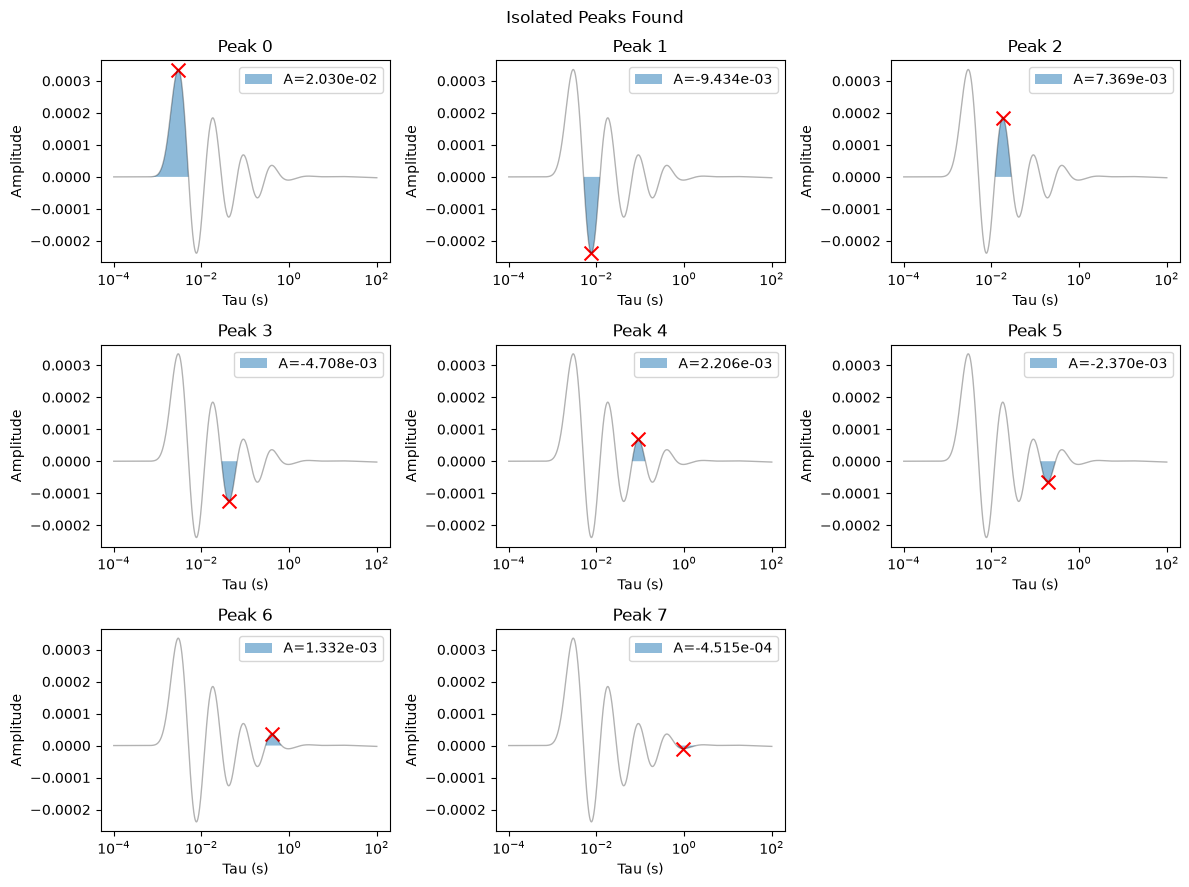

In [6]:
N_tau = 1000
lam = 1e-3
tau_min = 1e-4
tau_max = 100
N_exp_max = 1

df_fitB0, fitted_values, taus, x, props, pk, fit_params = fit.fit_inv(N_tau, 
                                                                   lam, 
                                                                   tau_min, 
                                                                   tau_max, 
                                                                   df_["B0(t)"], 
                                                                   df_["times (s)"],
                                                                   N_exp_max, 
                                                                   type_ = "B0")

display(df_fitB0)
fit.plot_fit(df_, taus, x, fitted_values, props, pk, N_exp_max, type_ = "B0")
var_max, std_diff = fit.plot_residuals(df_, fitted_values, type_ = "B0")
fit.plot_isolated_peaks(props, pk, x, taus)

### Save Offset df

In [7]:
fit.save_fit(df_fitB0, type_ = "B0")

Saved df to C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\data\Measure_EC\Xgrad_Xeddy/df_fitB0.csv
